# 04 - Error analysis of the PEFT LoRA

Loads the adapter trained in 03_lora_peft.ipynb, predicts the whole validation set (200 MolParser images),
sorts the failures into categories and shows examples of each category next to the ground truth.

In [1]:
from pathlib import Path

import torch

BASE_MODEL = "Qwen/Qwen3.5-0.8B-Base"
ADAPTER_DIR = Path("data/lora_0.8b_molparser_peft/adapter")
DATA_ROOT = Path("data").resolve()
DEVICE = "cuda"

## Model with the trained adapter

In [2]:
from peft import PeftModel
from transformers import AutoModelForImageTextToText, AutoProcessor

processor = AutoProcessor.from_pretrained(BASE_MODEL)
processor.tokenizer.padding_side = "right"
processor.chat_template = processor.tokenizer.chat_template
processor.image_processor.size = {"shortest_edge": 65536, "longest_edge": 512 * 32 * 32}  # same cap as in training

model = AutoModelForImageTextToText.from_pretrained(BASE_MODEL, dtype=torch.bfloat16).to(DEVICE)
model = PeftModel.from_pretrained(model, ADAPTER_DIR)
model.eval()
base = model.base_model.model

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

## Data

In [3]:
import json
import random

from huggingface_hub import hf_hub_download

index = hf_hub_download("EdisonScientific/glyph-datasets", "markush/train.jsonl", repo_type="dataset")
records = [r for r in map(json.loads, open(index)) if r["source"] == "molparser"]
random.Random(0).shuffle(records)
val_records = records[:200]  # the same validation split as in 03

## Predictions

In [4]:
from PIL import Image
from tqdm.auto import tqdm

IM_END = processor.tokenizer.convert_tokens_to_ids("<|im_end|>")


def prompt_text(user_text):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {
                "type": "text",
                "text": user_text
            }
        ]
    }]
    return processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)


@torch.no_grad()
def predict(r):
    image = Image.open(DATA_ROOT / r["images"][0]).convert("RGB")
    user_text = r["messages"][0]["content"].replace("<image>\n", "")
    inputs = processor(text=[prompt_text(user_text)], images=[image], return_tensors="pt").to(DEVICE)
    out = base.generate(**inputs, max_new_tokens=256, do_sample=False, eos_token_id=IM_END, pad_token_id=IM_END)
    return processor.tokenizer.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)


predictions = [predict(r) for r in tqdm(val_records)]
(ADAPTER_DIR.parent / "val_predictions.json").write_text(json.dumps(predictions))

  0%|          | 0/200 [00:00<?, ?it/s]

25377

## Failure categories

Every prediction goes into exactly one category, checked in this order: invalid output, exact match, wrong backbone,
and the rest (the backbone is right but something else differs from the ground truth).

In [5]:
import polars as pl

from glyph.markush.grading import grade


def category(sample, prediction):
    if not sample["valid_pred"]:
        return "invalid, no closing tag (loop)" if "</markush>" not in prediction else "invalid, other"
    if sample["cxsmiles_full_match"]:
        return "exact"
    if not sample["backbone_inchi_match"]:
        return "wrong backbone"
    return "right backbone, wrong rest"


results = []
for r, prediction in zip(val_records, predictions):
    target = r["messages"][1]["content"]
    sample = grade(prediction, target)["sample"]
    results.append({
        "id": r["source_id"],
        "image": DATA_ROOT / r["images"][0],
        "target": target,
        "prediction": prediction,
        "sample": sample,
        "category": category(sample, prediction),
    })

pl.DataFrame([{"category": r["category"]} for r in results]).group_by("category").len().sort("len", descending=True)

category,len
str,u32
"""wrong backbone""",100
"""exact""",70
"""right backbone, wrong rest""",30


## Gallery

Structures are drawn with RDKit

In [7]:
import base64
import re

from IPython.display import HTML, display
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D

from glyph.markush.inference import _standard_cxsmiles


def img(data, mime):
    # fixed-height box; large pictures are scaled down to fit, small ones keep their size
    src = base64.b64encode(data).decode()
    return (
        "<div style='height:260px; display:flex; align-items:center; justify-content:center'>"
        f"<img src='data:{mime};base64,{src}' style='max-width:100%; max-height:100%'></div>"
    )


def m_sections(standard):
    """Parse the m: part of a CXSMILES extension, e.g. m:0:11.12.13 -> [(0, [11, 12, 13])]."""
    match = re.search(r"m:((?:\d+:[\d.]+,?)+)", standard)
    if not match:
        return []
    pairs = [s.split(":") for s in match.group(1).strip(",").split(",")]
    return [(int(atom), [int(i) for i in ring.split(".")]) for atom, ring in pairs]


def depict(cxsmiles_opt, raw_text):
    """Draw a cxsmiles_opt string with RDKit. Atoms listed in the m: sections are highlighted,
    because the R group position is exactly what a plain depiction does not show."""
    standard = _standard_cxsmiles(cxsmiles_opt)
    mol = Chem.MolFromSmiles(standard.split(" |")[0]) if standard else None
    if mol is None:
        # cannot be converted or parsed, show raw text then
        return f"<code style='word-break:break-all'>{raw_text[:300]}</code>"

    labels = re.search(r"\$(.*?)\$", standard)
    for atom, label in zip(mol.GetAtoms(), labels.group(1).split(";") if labels else []):
        if label:
            atom.SetProp("atomLabel", label)

    sections = m_sections(standard)
    highlight = [atom for atom, ring in sections] + [i for atom, ring in sections for i in ring]
    # a wrong prediction can point to atoms that do not exist
    missing = [i for i in highlight if i >= mol.GetNumAtoms()]
    highlight = [i for i in highlight if i < mol.GetNumAtoms()]
    drawer = rdMolDraw2D.MolDraw2DCairo(500, 350)
    drawer.drawOptions().addAtomIndices = True
    drawer.DrawMolecule(mol, highlightAtoms=highlight)
    drawer.FinishDrawing()

    m_text = "; ".join(f"{atom} -> {'.'.join(map(str, ring))}" for atom, ring in sections) or "none"
    note = f" (atoms out of range: {missing})" if missing else ""
    return img(drawer.GetDrawingText(), "image/png") + f"<small>m: {m_text}{note}</small>"


def show(rs):
    cell = "border:1px solid #ccc; padding:6px; vertical-align:top; width:33%; background:white; color:black"
    html = "<table style='border-collapse:collapse; table-layout:fixed; width:100%'><tr>"
    for header in ["Image", "Ground truth", "LoRA prediction"]:
        html += f"<th style='{cell}'>{header}</th>"
    html += "</tr>"
    for r in rs:
        s = r["sample"]
        html += (
            f"<tr><td style='{cell}'><b>{r['id']}</b><br>{img(r['image'].read_bytes(), 'image/png')}</td>"
            f"<td style='{cell}'>{depict(s['gt_cxsmiles'], r['target'])}</td>"
            f"<td style='{cell}'>{depict(s['pred_cxsmiles'], r['prediction'])}"
            f"<br><small>{r['category']}, tanimoto: {s.get('tanimoto') or 0:.2f}</small></td></tr>"
        )
    display(HTML(html + "</table>"))


def pick(name, n=6):
    return [r for r in results if r["category"] == name][:n]

### Exact

Image,Ground truth,LoRA prediction
molparser-markush_train_079778,m: none,"m: noneexact, tanimoto: 1.00"
molparser-markush_train_027458,m: none,"m: noneexact, tanimoto: 1.00"
molparser-markush_train_052859,m: none,"m: noneexact, tanimoto: 1.00"

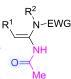
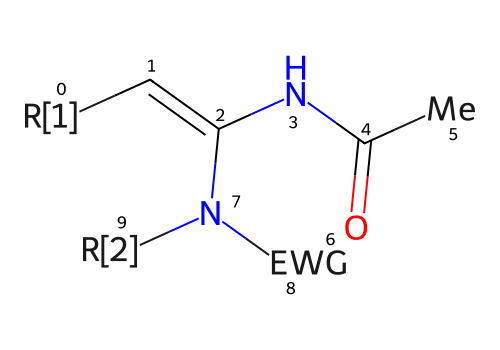
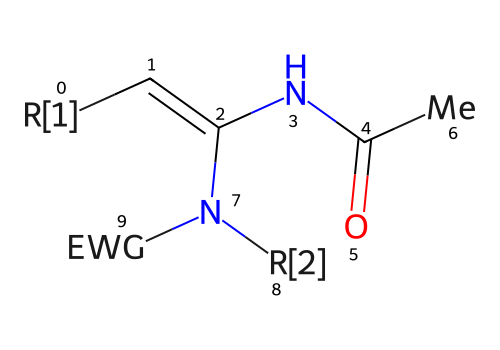
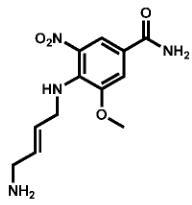
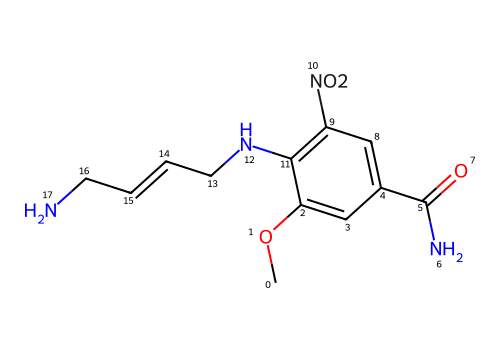
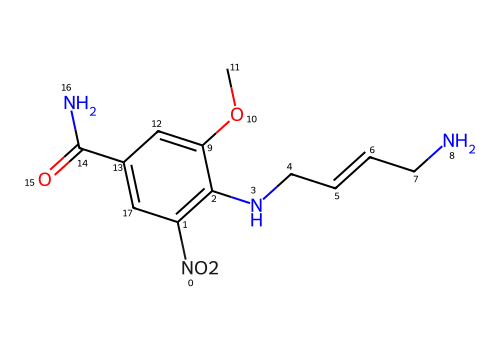
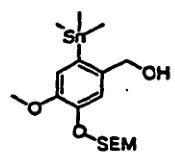
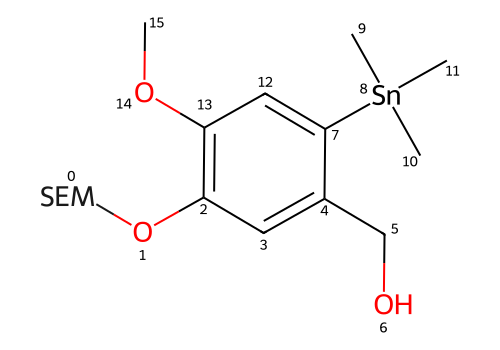
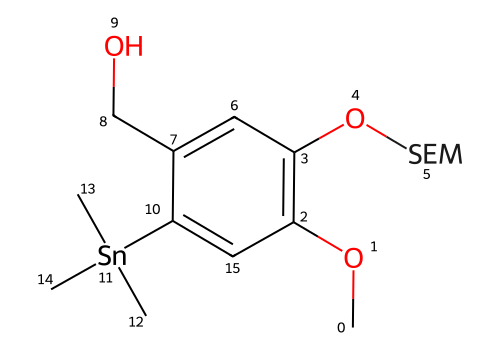

In [8]:
show(pick("exact", n=3))

### Right backbone, wrong rest

Image,Ground truth,LoRA prediction
molparser-markush_train_038977,m: none,"m: noneright backbone, wrong rest, tanimoto: 1.00"
molparser-markush_train_084086,m: none,"m: noneright backbone, wrong rest, tanimoto: 1.00"
molparser-markush_train_039908,m: none,"m: noneright backbone, wrong rest, tanimoto: 1.00"
molparser-markush_train_059609,m: none,"m: noneright backbone, wrong rest, tanimoto: 1.00"
molparser-markush_train_079697,m: 0 -> 11.12.13.14.15.16,"m: 0 -> 13.14.15.16.17.18right backbone, wrong rest, tanimoto: 0.96"
molparser-markush_train_071767,m: 0 -> 1.2.3.10.11.12,"m: 0 -> 1.2.3.4.13.14 (atoms out of range: [13, 14])right backbone, wrong rest, tanimoto: 0.92"

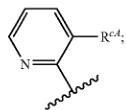
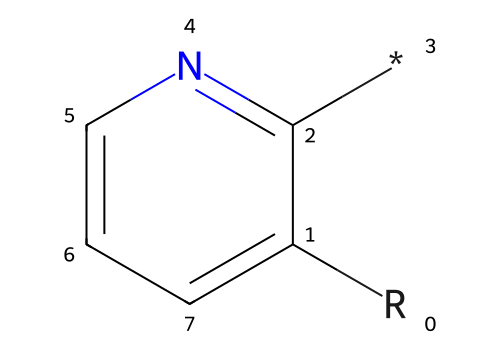
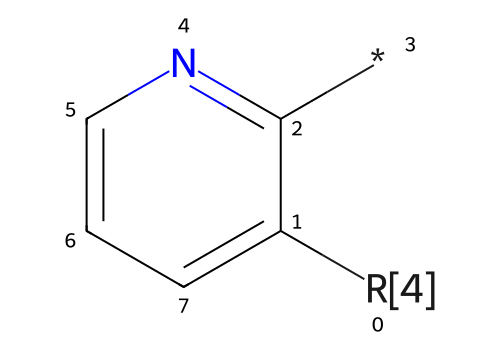
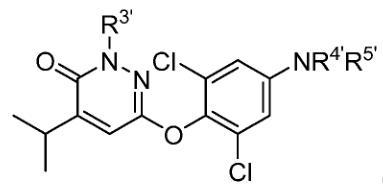
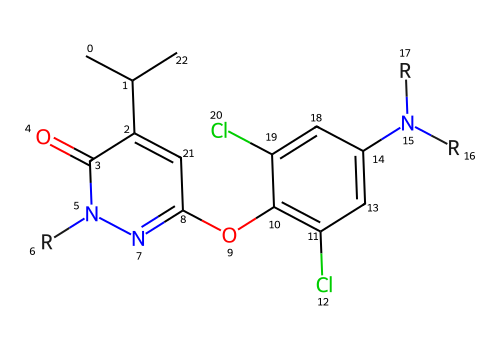
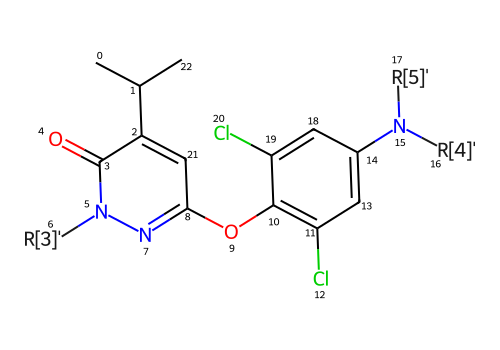
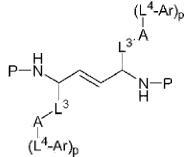
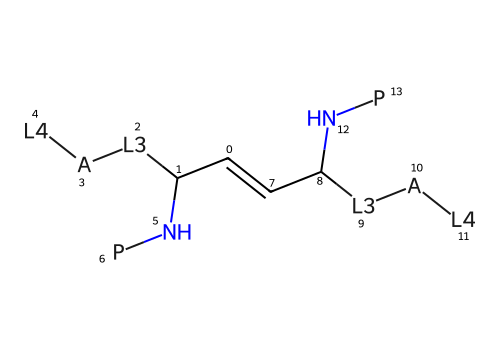
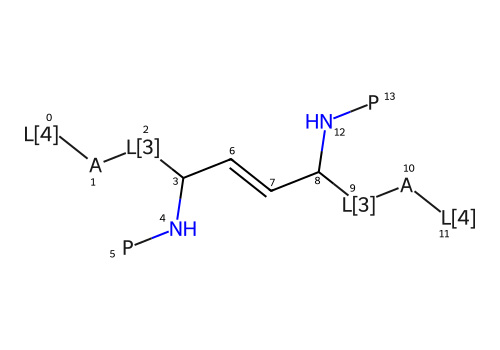
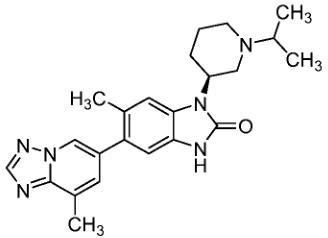
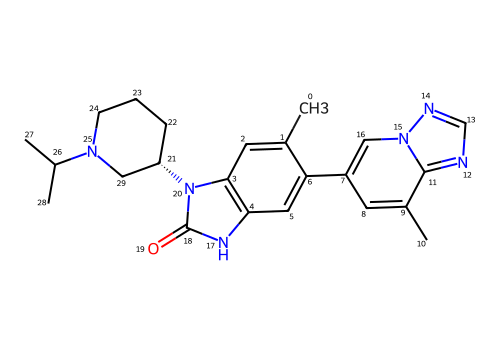
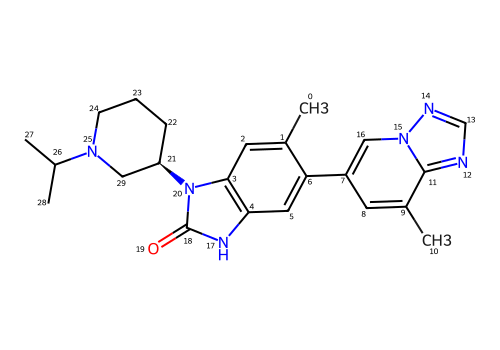
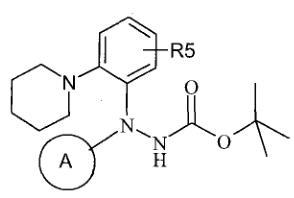
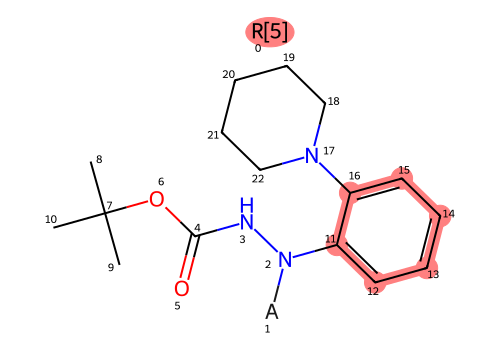
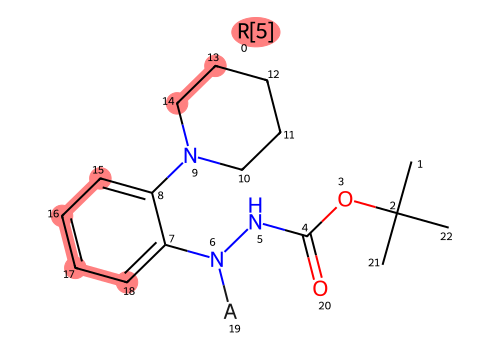
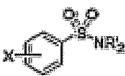
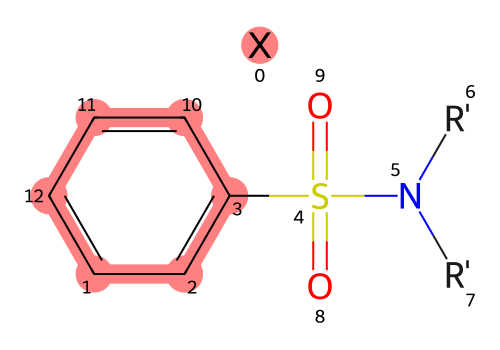
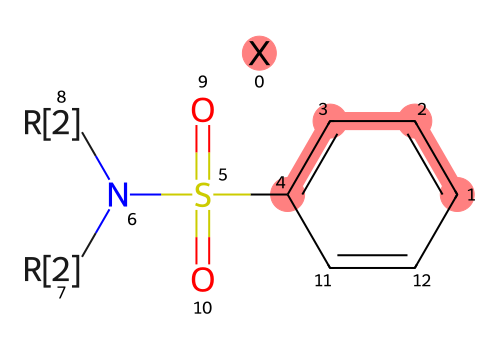

In [9]:
show(pick("right backbone, wrong rest"))

### Wrong backbone

Image,Ground truth,LoRA prediction
molparser-markush_train_064980,m: none,"m: nonewrong backbone, tanimoto: 0.86"
molparser-markush_train_067680,m: none,"m: nonewrong backbone, tanimoto: 0.41"
molparser-markush_train_003655,m: 0 -> 11.12.14.15.16.17,"m: 0 -> 13.14.15.16.17.18wrong backbone, tanimoto: 0.51"
molparser-markush_train_075466,m: none,"m: nonewrong backbone, tanimoto: 0.38"
molparser-markush_train_060282,m: 0 -> 25.26.27.28.29.30,"m: 0 -> 10.11.12.13.14.15wrong backbone, tanimoto: 0.91"
molparser-markush_train_010860,m: none,"m: nonewrong backbone, tanimoto: 0.62"

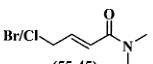
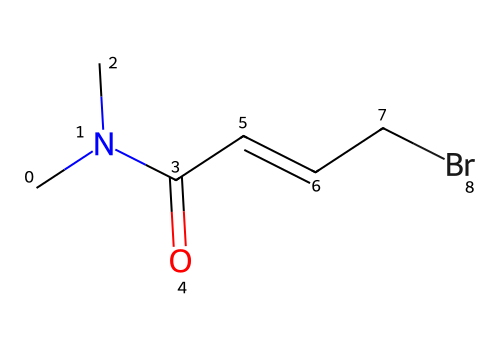
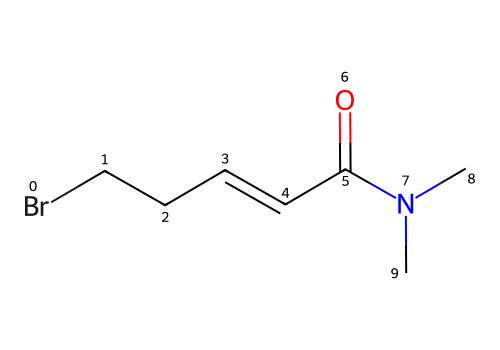
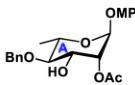
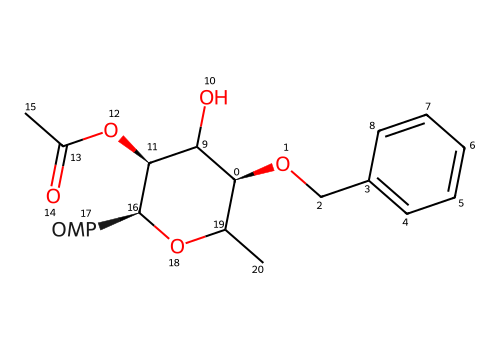
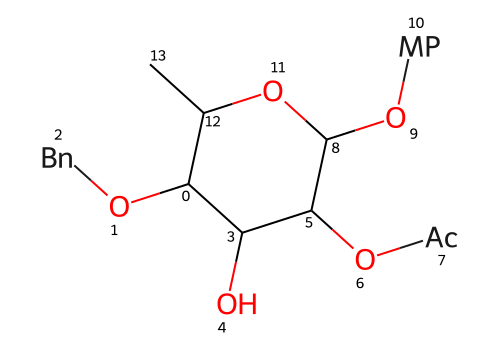
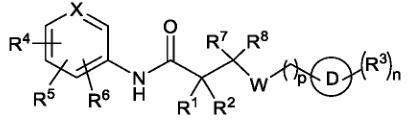
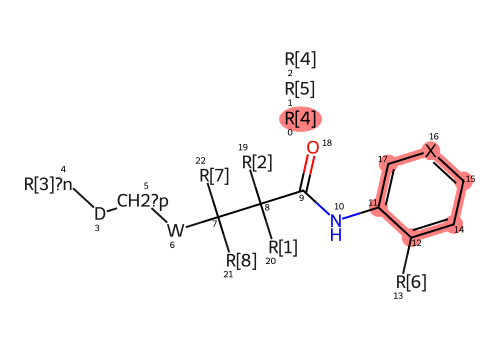
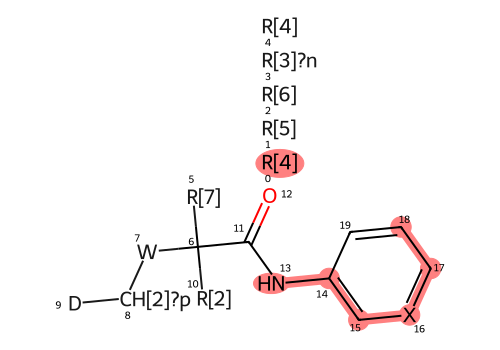
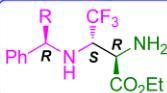
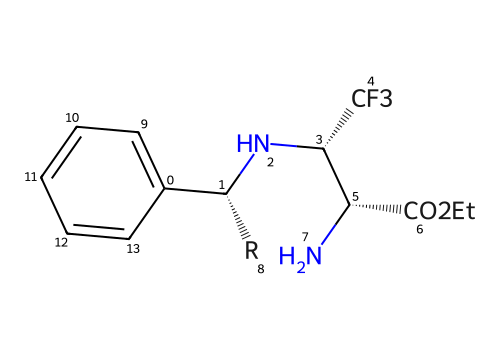
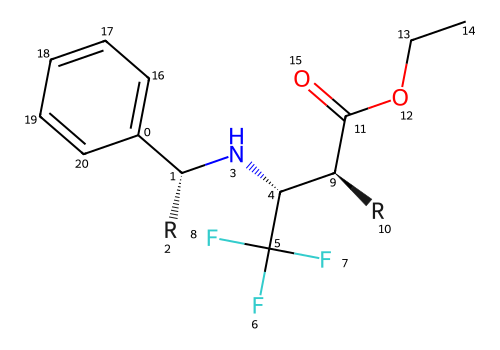
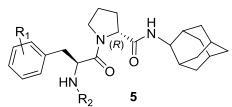
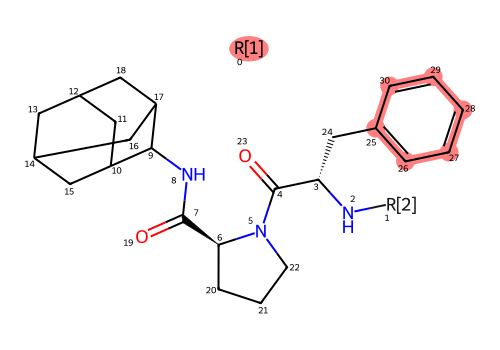
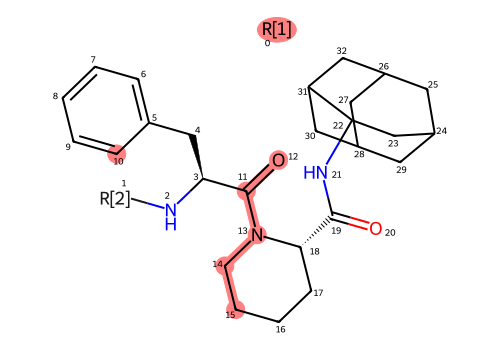
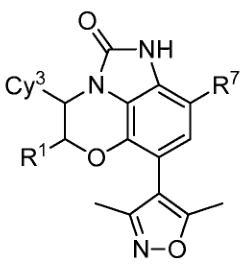
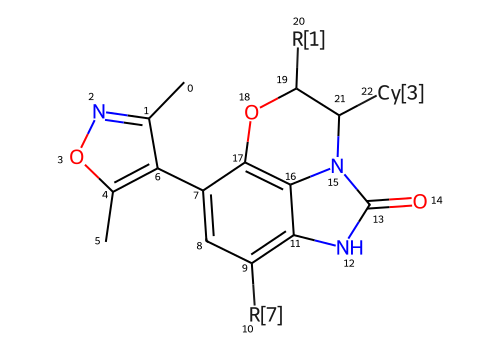
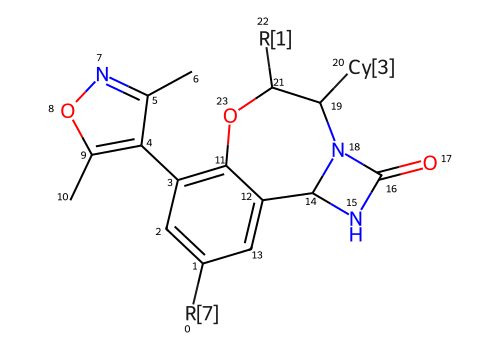

In [10]:
show(pick("wrong backbone"))

### Invalid output

In [11]:
invalid = [r for r in results if r["category"].startswith("invalid")]
show(invalid[:6])

Image,Ground truth,LoRA prediction


## M2S benchmark

The M2S test set (103 patent images) is the closest thing to a real test for MarkushGlyph. Its targets contain &lt;stable&gt; text
and Sg groups, which MolParser has neither of, so this shows what the MolParser-only training cannot teach.
The prompt is the benchmark one ("patent image"), a bit different from the MolParser prompt used in training.

In [12]:
from glyph.markush.eval.benchmark_data import materialize_benchmark

eval_jsonl, m2s_root = materialize_benchmark("m2s", Path("data/mini/m2s"))
m2s_items = [json.loads(line) for line in eval_jsonl.read_text().splitlines()]


@torch.no_grad()
def predict_m2s(item):
    image = Image.open(m2s_root / item["image"]).convert("RGB")
    inputs = processor(text=[prompt_text(item["prompt"])], images=[image], return_tensors="pt").to(DEVICE)
    # targets with <stable> text are longer than MolParser ones, so allow more new tokens than before
    out = base.generate(**inputs, max_new_tokens=768, do_sample=False, eos_token_id=IM_END, pad_token_id=IM_END)
    return processor.tokenizer.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)


m2s_predictions = [predict_m2s(item) for item in tqdm(m2s_items)]
(ADAPTER_DIR.parent / "m2s_predictions.json").write_text(json.dumps(m2s_predictions))

  0%|          | 0/103 [00:00<?, ?it/s]

17540

In [13]:
m2s_results = []
for item, prediction in zip(m2s_items, m2s_predictions):
    sample = grade(prediction, item["annotation"])["sample"]
    m2s_results.append({
        "id": f"m2s-{item['id']}",
        "image": m2s_root / item["image"],
        "target": item["annotation"],
        "prediction": prediction,
        "sample": sample,
        "category": category(sample, prediction),
    })

# invalid predictions have no stable_* fields, count them as 0
metrics = ["valid_pred", "backbone_inchi_match", "cxsmiles_full_match", "stable_equality", "stable_recall", "markush_full_match"]
pl.DataFrame([{m: float(r["sample"].get(m) or 0) for m in metrics} for r in m2s_results]).mean()

valid_pred,backbone_inchi_match,cxsmiles_full_match,stable_equality,stable_recall,markush_full_match
f64,f64,f64,f64,f64,f64
0.970874,0.291262,0.009709,0.0,0.0,0.0


Compared with the released MarkushGlyph on the 50 M2S images drawn in 01_comparison.ipynb.
exact is cxsmiles_full_match, the same as in notebook 01.

In [14]:
released = {r["id"]: r["markush_score"] for r in json.load(open("data/mini/results.json")) if r["kind"] == "markush"}
overlap = [r for r in m2s_results if r["id"] in released]
ours = {"valid": "valid_pred", "backbone": "backbone_inchi_match", "exact": "cxsmiles_full_match"}

pl.DataFrame([
    {"model": "released MarkushGlyph", **{k: sum(released[r["id"]][k] for r in overlap) / len(overlap) for k in ours}},
    {"model": "our LoRA (MolParser only)", **{k: sum(bool(r["sample"][v]) for r in overlap) / len(overlap) for k, v in ours.items()}},
])

model,valid,backbone,exact
str,f64,f64,f64
"""released MarkushGlyph""",1.0,0.68,0.64
"""our LoRA (MolParser only)""",0.96,0.22,0.0


In [15]:
pl.DataFrame([{"category": r["category"]} for r in m2s_results]).group_by("category").len().sort("len", descending=True)

category,len
str,u32
"""wrong backbone""",70
"""right backbone, wrong rest""",29
"""invalid, no closing tag (loop)""",3
"""exact""",1


### M2S examples

Image,Ground truth,LoRA prediction
m2s-0,m: none,"m: nonewrong backbone, tanimoto: 0.84"
m2s-2,m: 1 -> 4.5.6.7.8.9,"m: 0 -> 3.4.5.6.7.8wrong backbone, tanimoto: 0.80"
m2s-3,m: 1 -> 4.5.6.7.8.9,"m: 0 -> 3.4.5.6.7.8wrong backbone, tanimoto: 0.80"
m2s-7,m: 1 -> 23.24.25.26.27.28,"m: 0 -> 13.14.15.16.17.18wrong backbone, tanimoto: 0.00"

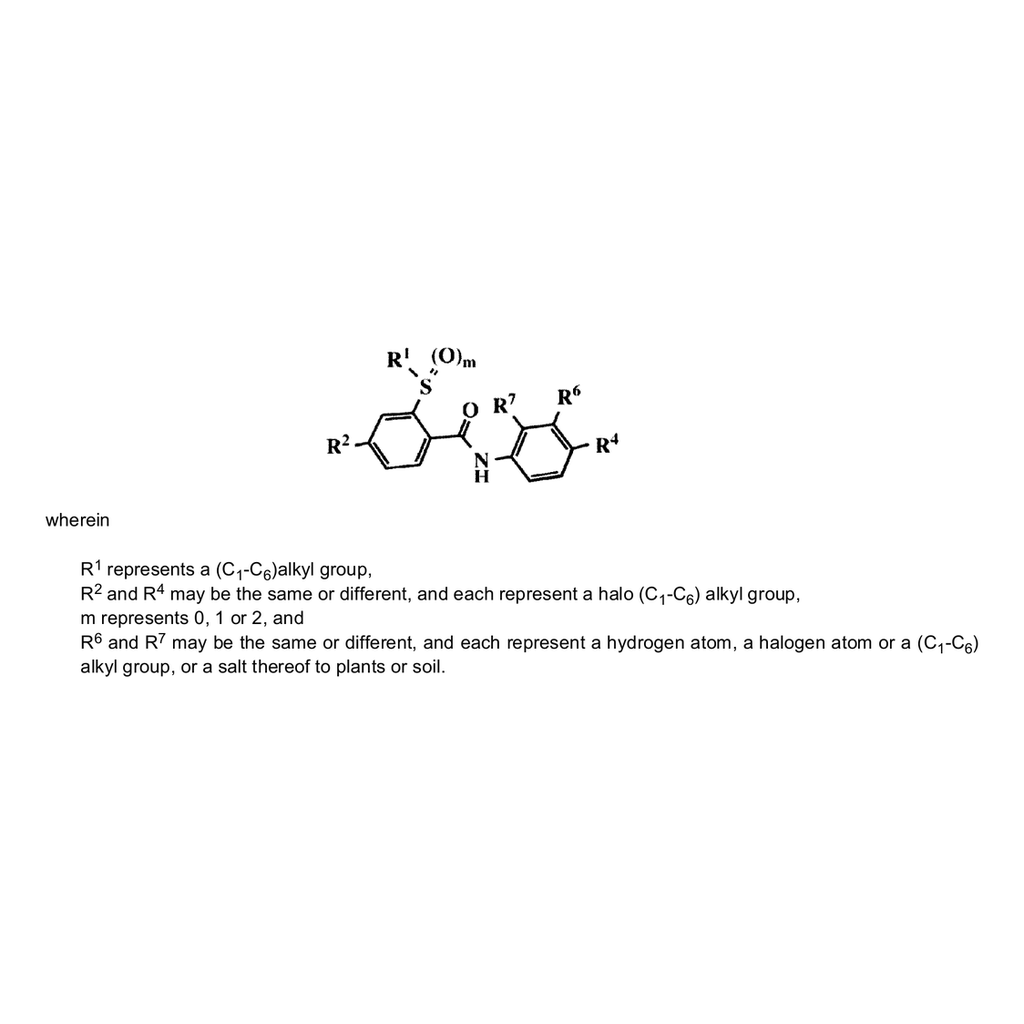
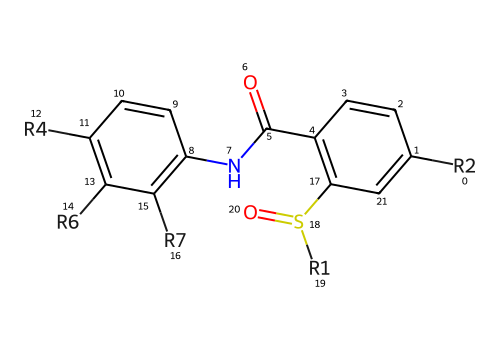
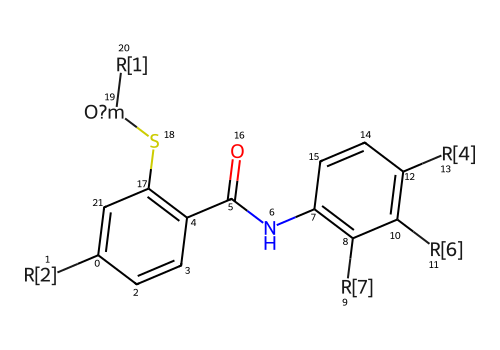
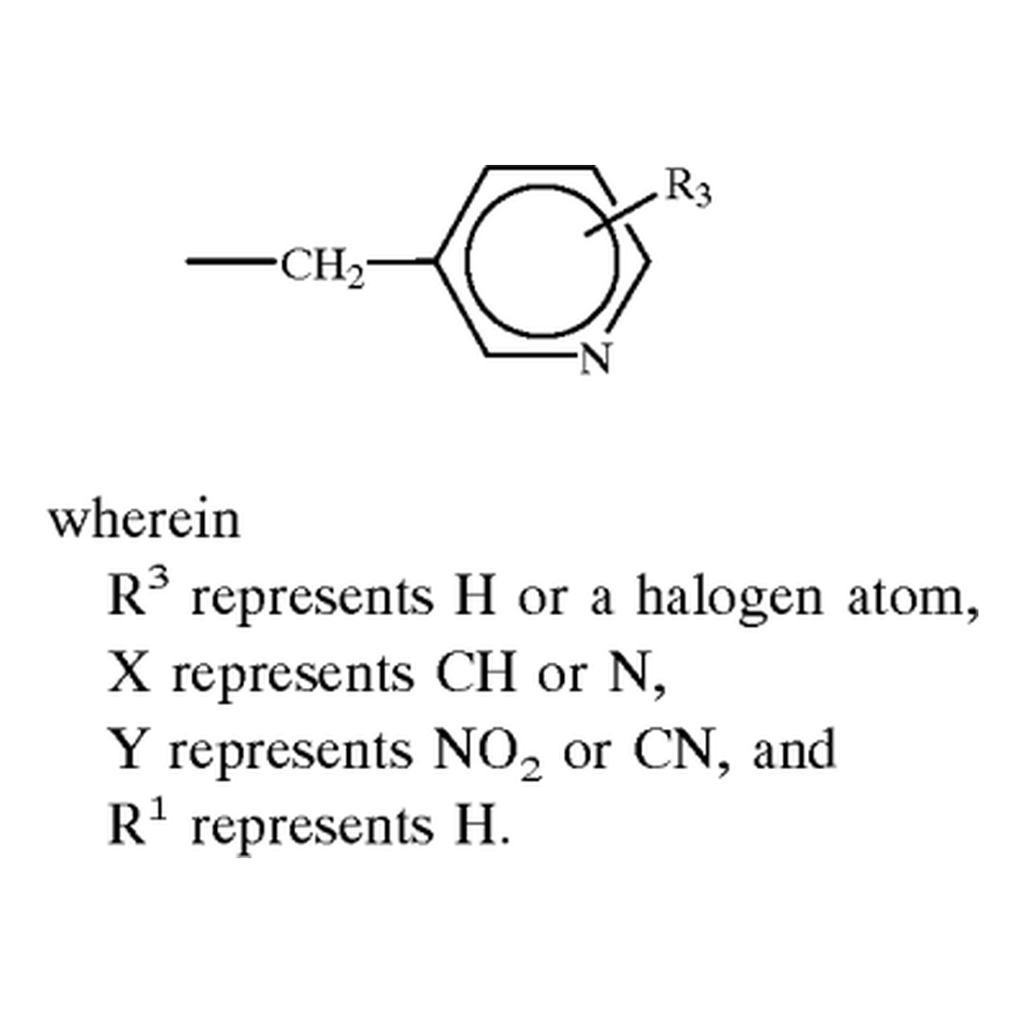
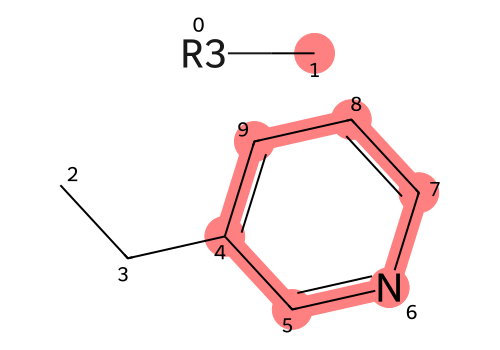
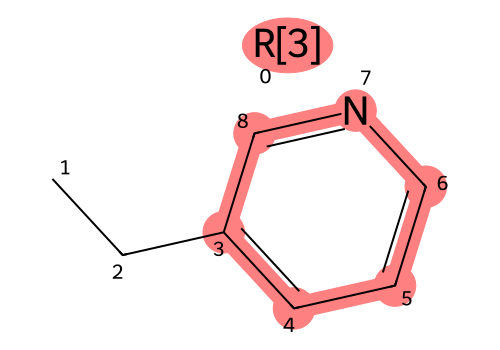
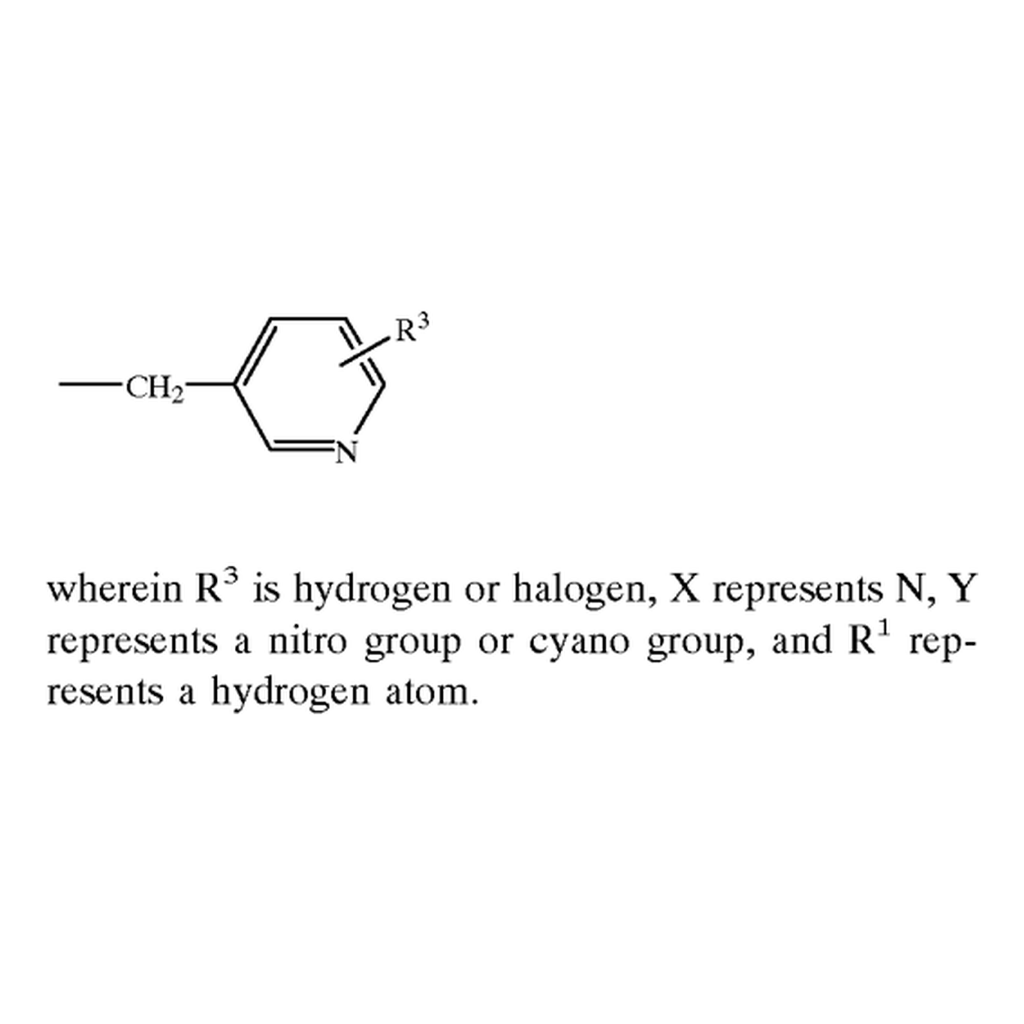
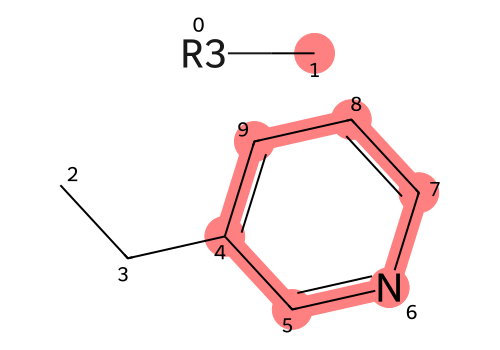
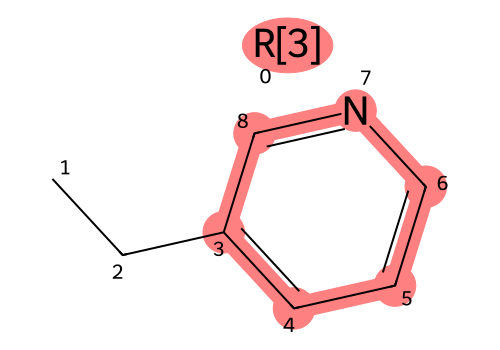
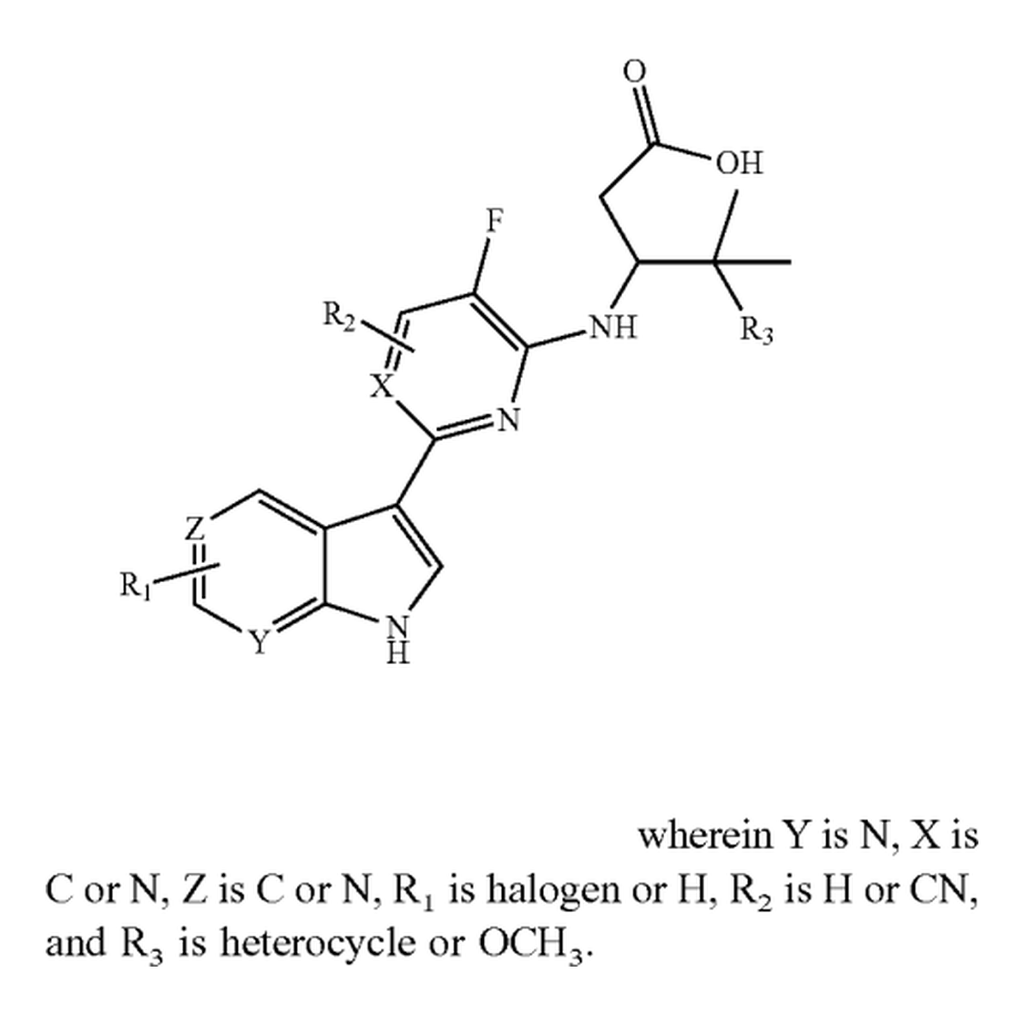
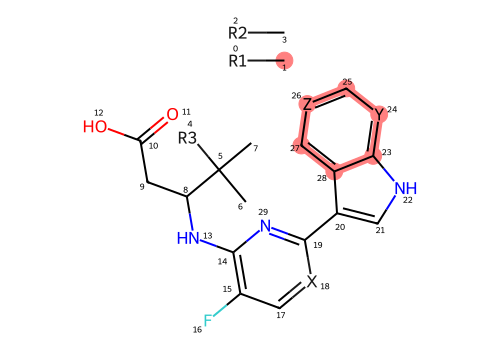
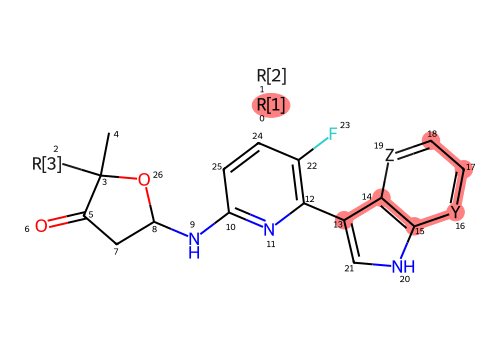

In [16]:
show([r for r in m2s_results if r["category"] == "wrong backbone"][:4])

Image,Ground truth,LoRA prediction
m2s-1,m: none,"m: noneright backbone, wrong rest, tanimoto: 0.10"
m2s-5,m: none,"m: noneright backbone, wrong rest, tanimoto: 1.00"
m2s-6,m: none,"m: noneright backbone, wrong rest, tanimoto: 1.00"
m2s-8,m: none,"m: noneright backbone, wrong rest, tanimoto: 1.00"

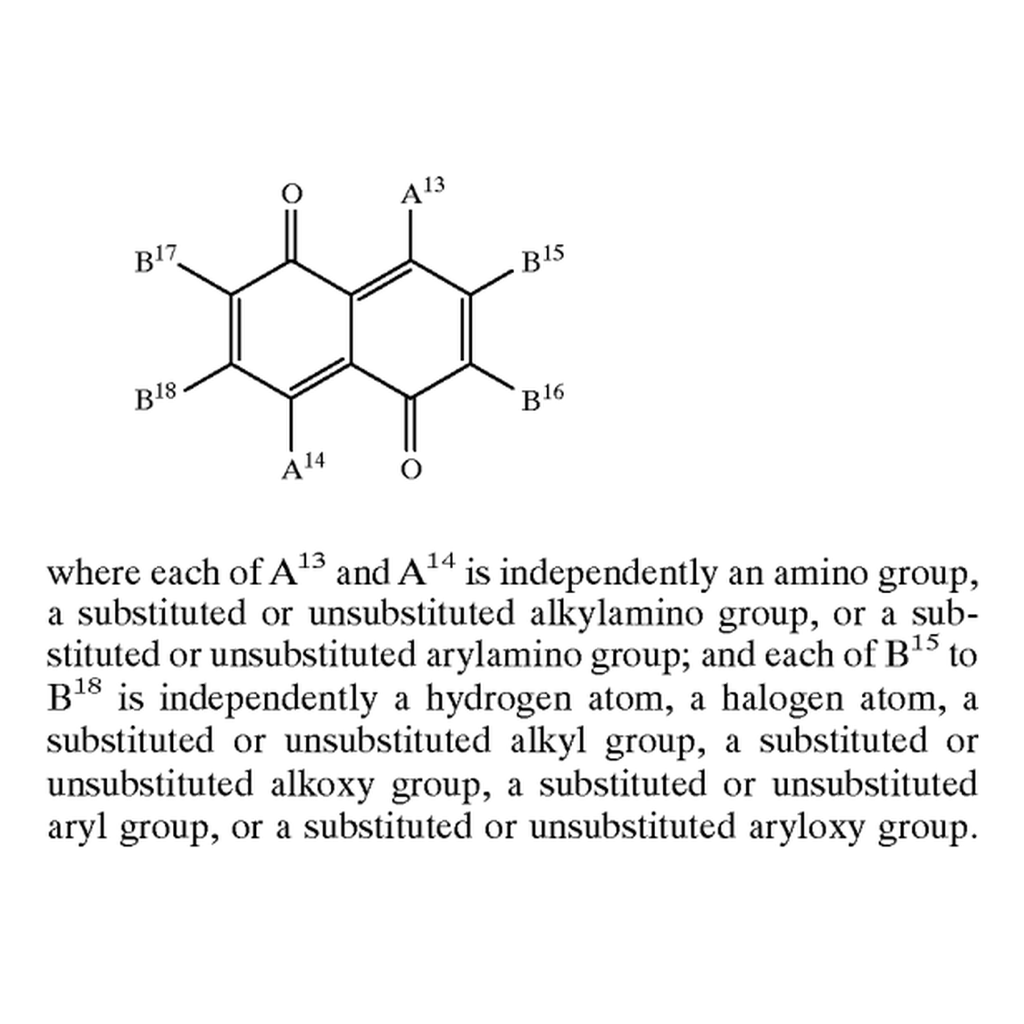
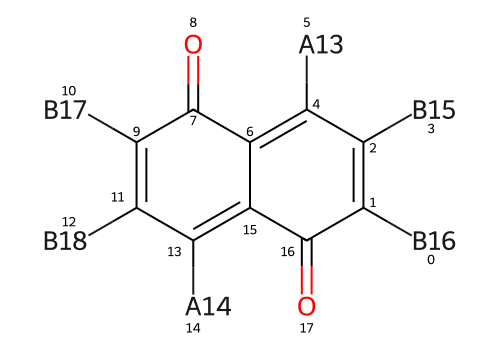
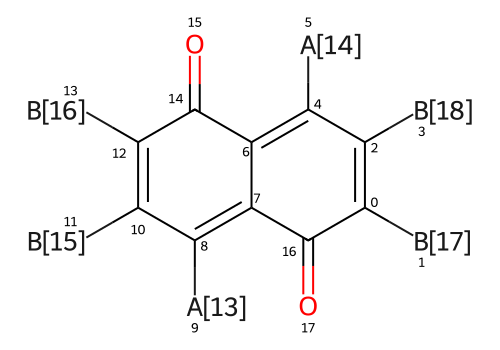
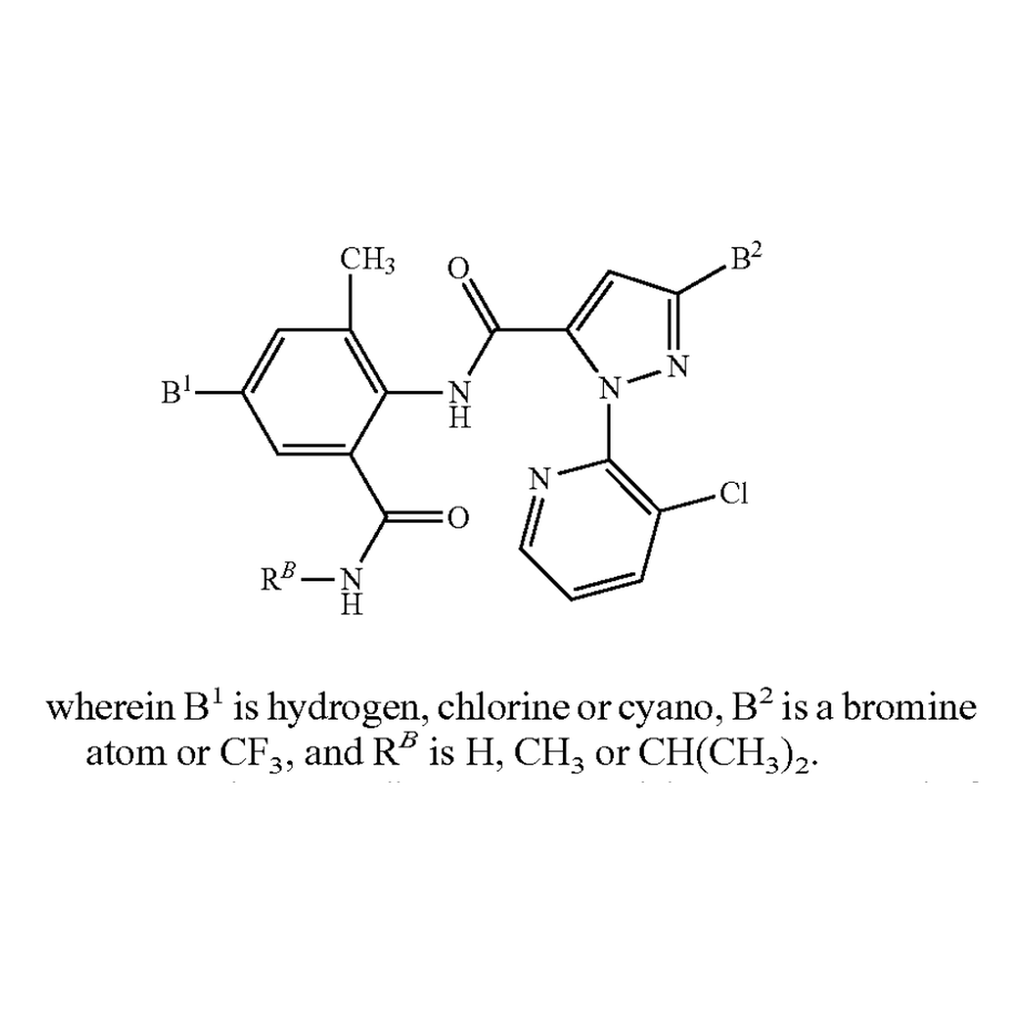
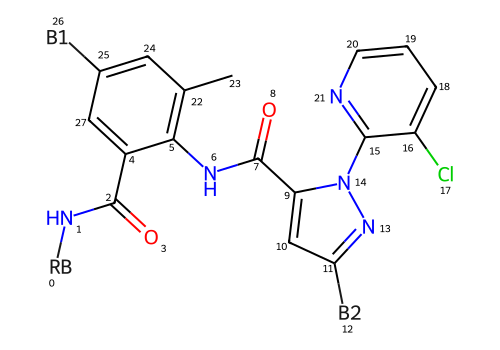
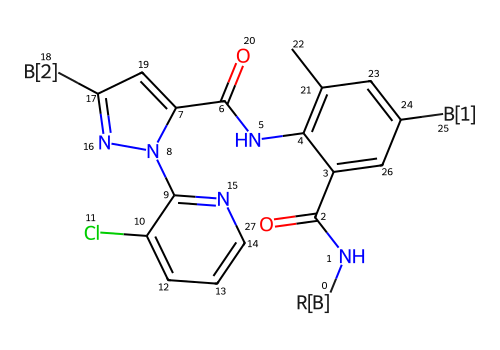
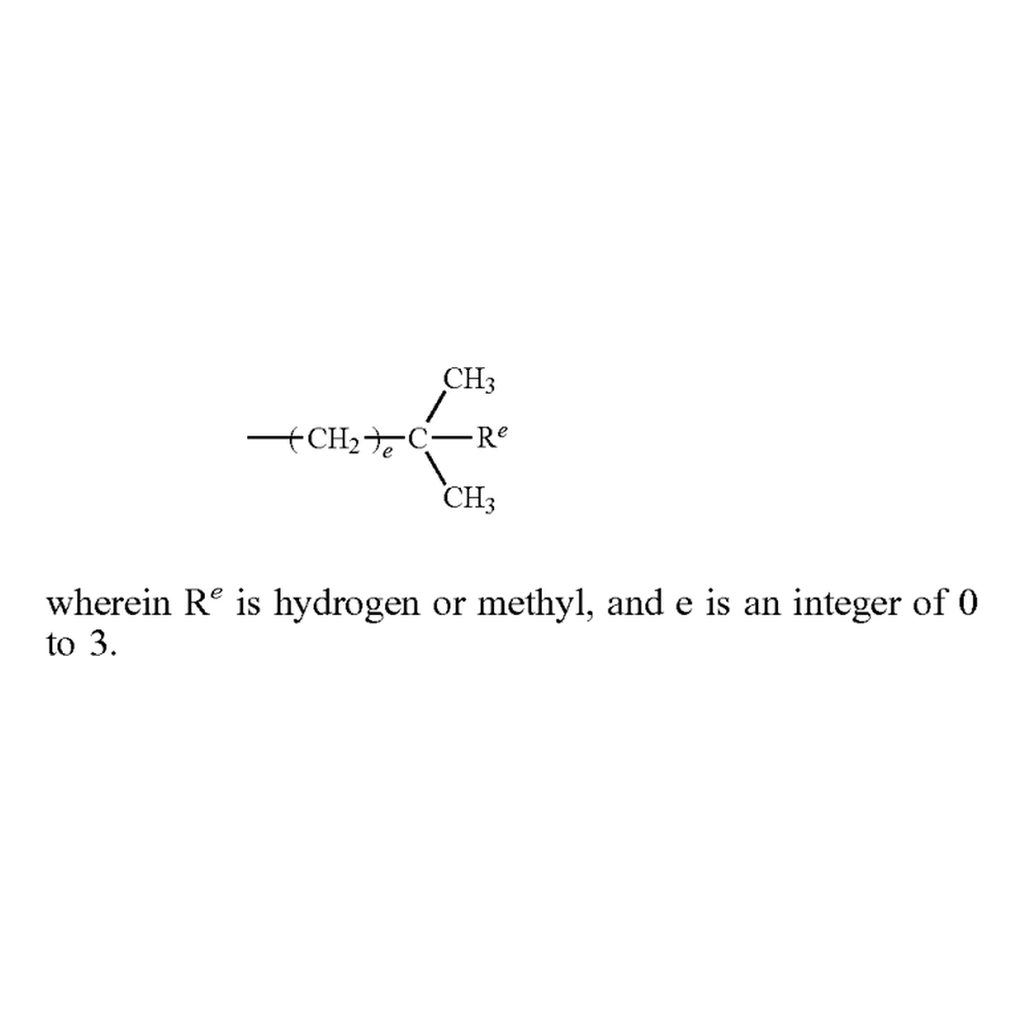
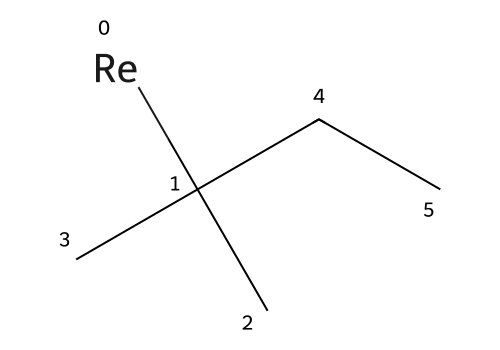
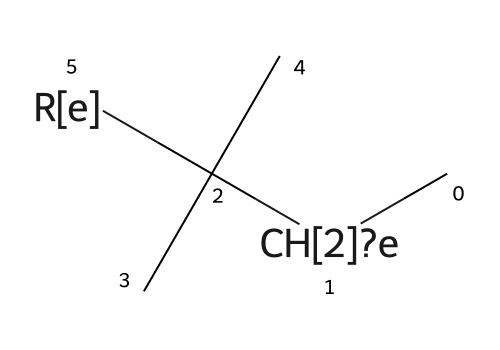
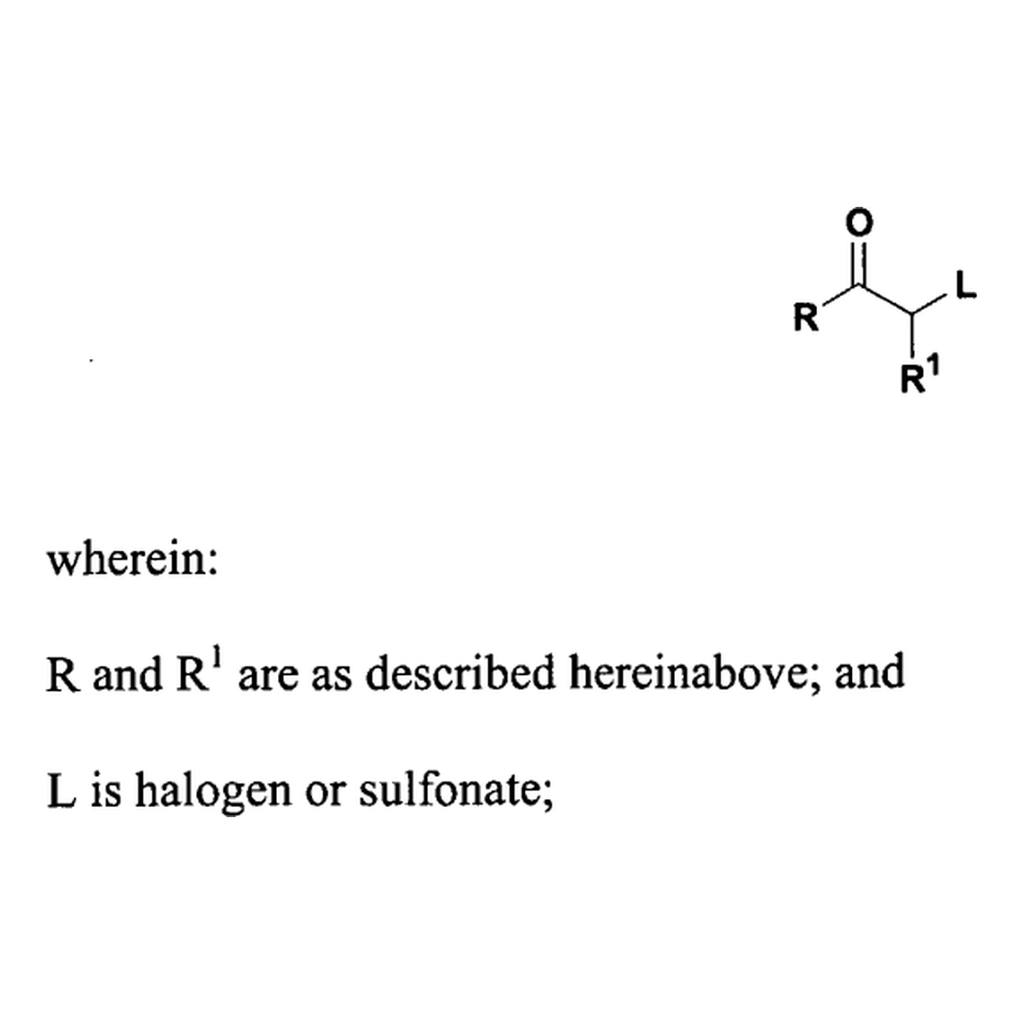
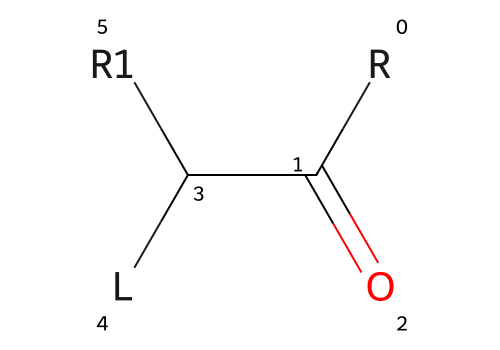
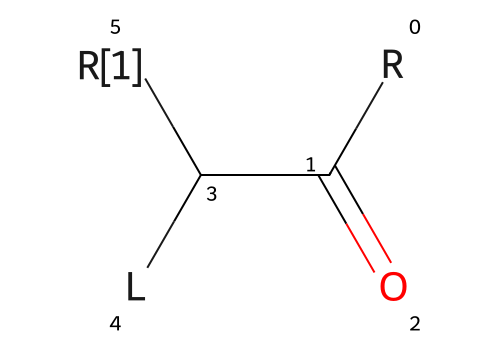

In [17]:
show([r for r in m2s_results if r["category"] == "right backbone, wrong rest"][:4])